In [41]:
# Load the data
import pandas as pd

df = pd.read_csv('../data/BankChurners.csv', index_col='CLIENTNUM')
df.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
CLIENTNUM,,,,,,,,,,,,,,,,,,,,
768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


In [42]:
# CREATE TARGET VARIABLE

X = df.drop('Attrition_Flag', axis=1)
y = (df['Attrition_Flag'] == 'Attrited Customer').astype(int)



In [43]:
# CHECK TARGET DISRIBUTION
counts = y.value_counts()
pc = y.value_counts(normalize=True) * 100

print('1 is runaway customer, 0 is existing customer')
print(counts)
print(pc)

1 is runaway customer, 0 is existing customer
Attrition_Flag
0    8500
1    1627
Name: count, dtype: int64
Attrition_Flag
0    83.934038
1    16.065962
Name: proportion, dtype: float64


C:\Users\USER\AppData\Local\Temp\ipykernel_13352\426519900.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette='Set2')


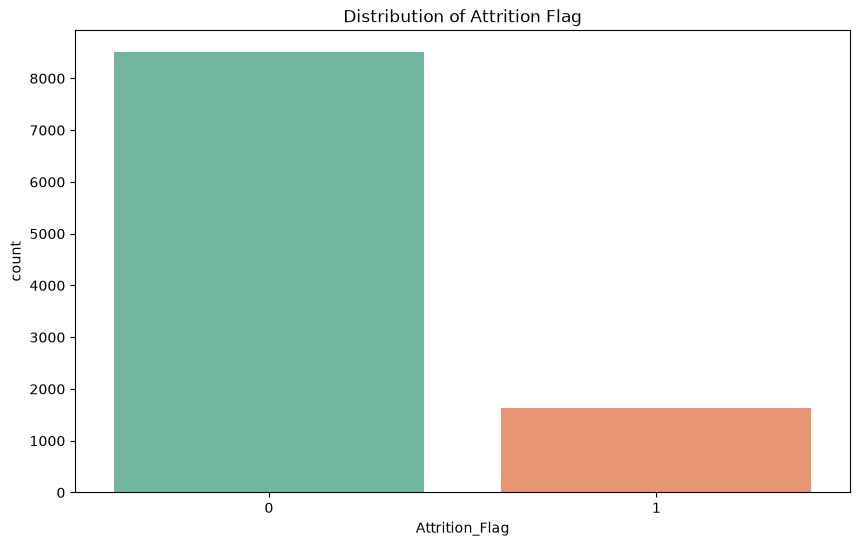

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(x=y, palette='Set2')
plt.title('Distribution of Attrition Flag')
plt.show()

In [47]:
# ESTABLISH BASELINE
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier

# convert to cat type
for col in X.select_dtypes(include=['object', 'category']).columns:
    X[col] = X[col].astype('category')

bs_pos_weight = (1 - y.mean()) / y.mean()

bs_model = XGBClassifier(scale_pos_weight=bs_pos_weight, max_depth=5, learning_rate=0.05, n_estimators=300, random_state=42, enable_categorical=True)
bs_model.fit(X, y)

cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
bs_y_pred = cross_val_predict(bs_model, X, y, cv=cv_stratified)

# Get out-of-fold probabilities
bs_y_proba = cross_val_predict(bs_model, X, y, cv=cv_stratified, method='predict_proba')[:, 1]

# Print full classification report
print("Baseline Classification Report:")
print(classification_report(y, bs_y_pred, target_names=['Existing', 'Churned']))

# 4. Print AUC-ROC
auc = roc_auc_score(y, bs_y_proba)
print(f"Baseline AUC-ROC: {auc:.4f}")

Baseline Classification Report:
              precision    recall  f1-score   support

    Existing       0.99      0.97      0.98      8500
     Churned       0.87      0.94      0.90      1627

    accuracy                           0.97     10127
   macro avg       0.93      0.96      0.94     10127
weighted avg       0.97      0.97      0.97     10127

Baseline AUC-ROC: 0.9932


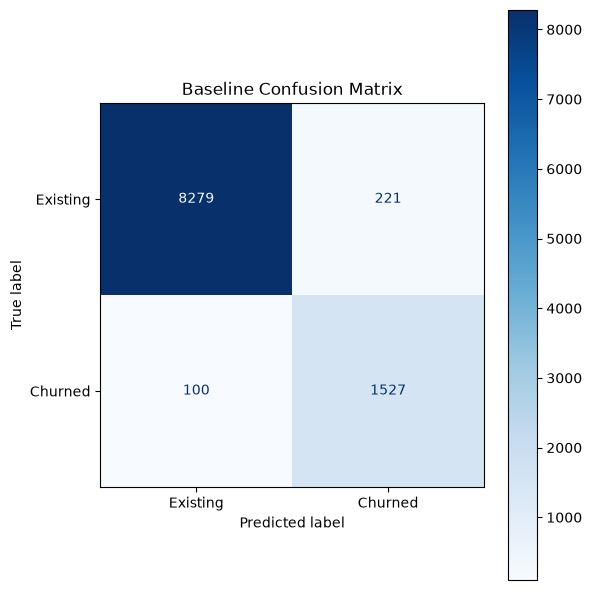

In [48]:
# BASELINE CONFUSION MATRIX
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y, bs_y_pred, display_labels=['Existing', 'Churned'], cmap='Blues', ax=ax)
plt.title('Baseline Confusion Matrix')
plt.tight_layout()
plt.show()

In [ ]:
# FEATURE IMPORTANCE OF BASELINE MODEL
imp = bs_model.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': imp})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print(feature_importance_df.to_string(index=False))

                 Feature  Importance
          Total_Trans_Ct    0.319035
     Total_Revolving_Bal    0.152208
Total_Relationship_Count    0.087215
         Total_Trans_Amt    0.081145
     Total_Ct_Chng_Q4_Q1    0.050771
                  Gender    0.044703
  Months_Inactive_12_mon    0.040623
    Total_Amt_Chng_Q4_Q1    0.036721
         Avg_Open_To_Buy    0.029641
   Contacts_Count_12_mon    0.026080
            Customer_Age    0.025238
            Credit_Limit    0.020387
           Card_Category    0.018787
          Months_on_book    0.015641
          Marital_Status    0.015413
   Avg_Utilization_Ratio    0.011545
         Dependent_count    0.009672
         Income_Category    0.007758
         Education_Level    0.007417


In [26]:
from IPython.display import display
display(X.info())

<class 'pandas.DataFrame'>
Index: 10127 entries, 768805383 to 714337233
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Customer_Age              10127 non-null  int64   
 1   Gender                    10127 non-null  category
 2   Dependent_count           10127 non-null  int64   
 3   Education_Level           10127 non-null  category
 4   Marital_Status            10127 non-null  category
 5   Income_Category           10127 non-null  category
 6   Card_Category             10127 non-null  category
 7   Months_on_book            10127 non-null  int64   
 8   Total_Relationship_Count  10127 non-null  int64   
 9   Months_Inactive_12_mon    10127 non-null  int64   
 10  Contacts_Count_12_mon     10127 non-null  int64   
 11  Credit_Limit              10127 non-null  float64 
 12  Total_Revolving_Bal       10127 non-null  int64   
 13  Avg_Open_To_Buy           10127 non-null  float64 

None

In [27]:
# get num and cat cols

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(include=['category']).columns.tolist()

print(num_cols)
print(cat_cols)

['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']


In [28]:
# get nunique
for i in cat_cols:
    print(i, X[i].nunique())

Gender 2
Education_Level 7
Marital_Status 4
Income_Category 6
Card_Category 4


In [29]:
# mutual info
from sklearn.feature_selection import mutual_info_regression
def mi_scores(X, y):
    # copy X
    X = X.copy()
    # label encode categoricals
    for colname in X.select_dtypes(['object', 'category']):
        X[colname], _ = X[colname].factorize()

    # add feature names to the scores
    discrete_features = X.dtypes == int
    mi = mutual_info_regression(X, y, discrete_features=discrete_features)
    mi = pd.Series(mi, index=X.columns, name='MI Scores')
    mi = mi.sort_values(ascending=False)
    return mi
# Get MI scores
print(mi_scores(X, y))

Total_Trans_Amt             0.275961
Total_Revolving_Bal         0.113026
Total_Trans_Ct              0.111128
Total_Ct_Chng_Q4_Q1         0.089937
Avg_Utilization_Ratio       0.043069
Total_Amt_Chng_Q4_Q1        0.034050
Contacts_Count_12_mon       0.029003
Months_Inactive_12_mon      0.025516
Avg_Open_To_Buy             0.021341
Total_Relationship_Count    0.017184
Credit_Limit                0.010745
Marital_Status              0.005868
Gender                      0.005604
Months_on_book              0.000454
Customer_Age                0.000000
Dependent_count             0.000000
Income_Category             0.000000
Card_Category               0.000000
Education_Level             0.000000
Name: MI Scores, dtype: float64


In [ ]:
X = X.drop(columns=['Avg_Open_To_Buy', 'Gender', 'Marital_Status'])
print(X.columns)

Index(['Customer_Age', 'Dependent_count', 'Income_Category', 'Card_Category',
       'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon',
       'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal',
       'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct',
       'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio'],
      dtype='str')


In [52]:
# clustering
'''from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

behaviour_features = ['Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
seg_features = X[behaviour_features].copy()

scaler = StandardScaler()
scaled_features = scaler.fit_transform(seg_features)
scaled_features.shape'''

"from sklearn.cluster import KMeans\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.metrics import silhouette_score\n\nbehaviour_features = ['Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']\nseg_features = X[behaviour_features].copy()\n\nscaler = StandardScaler()\nscaled_features = scaler.fit_transform(seg_features)\nscaled_features.shape"

In [53]:
'''silhouette_scores = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(scaled_features)
    silhouette_scores[k] = silhouette_score(scaled_features, labels)

plt.figure(figsize=(7, 4))
plt.plot(list(silhouette_scores.keys()), list(silhouette_scores.values()), marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette score by k picking the number of segments')
plt.axvline(x=5, color='red', linestyle='--', alpha=0.5, label='Chosen k=5')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for k, score in silhouette_scores.items():
    marker = '  <- chosen' if k == 5 else ''
    print(f"k={k}: silhouette={score:.4f}{marker}")'''

'silhouette_scores = {}\nfor k in range(2, 8):\n    km = KMeans(n_clusters=k, random_state=42, n_init=10)\n    labels = km.fit_predict(scaled_features)\n    silhouette_scores[k] = silhouette_score(scaled_features, labels)\n\nplt.figure(figsize=(7, 4))\nplt.plot(list(silhouette_scores.keys()), list(silhouette_scores.values()), marker=\'o\')\nplt.xlabel(\'Number of clusters (k)\')\nplt.ylabel(\'Silhouette score\')\nplt.title(\'Silhouette score by k picking the number of segments\')\nplt.axvline(x=5, color=\'red\', linestyle=\'--\', alpha=0.5, label=\'Chosen k=5\')\nplt.legend()\nplt.grid(alpha=0.3)\nplt.show()\n\nfor k, score in silhouette_scores.items():\n    marker = \'  <- chosen\' if k == 5 else \'\'\n    print(f"k={k}: silhouette={score:.4f}{marker}")'

In [54]:
'''kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
X['Cluster'] = kmeans.fit_predict(scaled_features)

best_silhouette = silhouette_score(scaled_features, X['Cluster'])
print(f"best silhouette:(k=5) {best_silhouette}")
X['Cluster'].value_counts().sort_index()'''

'kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)\nX[\'Cluster\'] = kmeans.fit_predict(scaled_features)\n\nbest_silhouette = silhouette_score(scaled_features, X[\'Cluster\'])\nprint(f"best silhouette:(k=5) {best_silhouette}")\nX[\'Cluster\'].value_counts().sort_index()'

In [76]:
X['Card_Category'].value_counts()

Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64

In [77]:
# Classification using xgboost
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler


num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Ordinal encode "Card Category"
nominal_cols = [col for col in cat_cols if col != "Card_Category"]


# preprocess numerical data
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

# preprocess card category
cc_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                           ('ordinal', OrdinalEncoder(categories=[["BLue", "Silver", "Gold", "Platinum"]], handle_unknown='use_encoded_value', unknown_value=-1 ))])

# preprocess cat data
nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# join
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, num_cols),
    ('cat', nominal_transformer, cat_cols),
    ('card category', cc_transformer, ['Card_Category'])
])


# calc weight to handle imbalance
pos_weight = (len(y) - y.sum()) / y.sum()

# transform train and test
deployable_model = Pipeline([('preprocessor', preprocessor),
                             ('classifier', XGBClassifier(scale_pos_weight=pos_weight,
                                                         max_depth=5,
                                                         learning_rate=0.03,
                                                         n_estimators=100,
                                                         random_state=42))
                                                         ])



In [78]:
# predict
import joblib


# Predict
y_pred = cross_val_predict(deployable_model, X, y, cv=cv_stratified)
y_prob = cross_val_predict(deployable_model, X, y, cv=cv_stratified, method='predict_proba')[:, 1]

# Evaluate
print("Classification Report:")
print(classification_report(y, y_pred, target_names=['Existing', 'Churned']))

print(f"AUC-ROC: {roc_auc_score(y, y_prob):.4f}")

Classification Report:
              precision    recall  f1-score   support

    Existing       0.99      0.95      0.97      8500
     Churned       0.77      0.94      0.85      1627

    accuracy                           0.95     10127
   macro avg       0.88      0.94      0.91     10127
weighted avg       0.95      0.95      0.95     10127

AUC-ROC: 0.9867


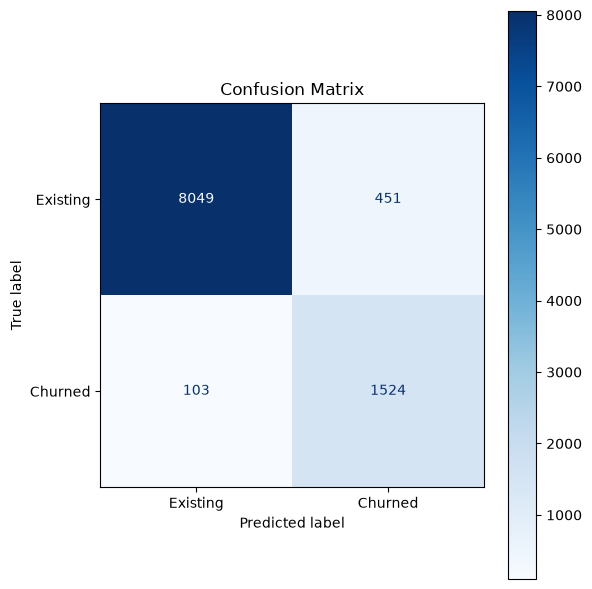

In [79]:
# confusion matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=['Existing', 'Churned'], cmap='Blues', ax=ax)
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

In [80]:
# FIT AND DEPLOY
deployable_model.fit(X,y)
joblib.dump(deployable_model, 'churn_model.joblib')

['churn_model.joblib']

In [81]:
print(num_cols)
print(cat_cols)

['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
['Income_Category', 'Card_Category']
